In [32]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import lil_matrix
from scipy.sparse.linalg import eigsh
from scipy.sparse.csgraph import shortest_path
from scipy.stats import linregress

import os
import gc

L_list = [32, 48, 64, 80]
W_list = [4, 6, 8, 10]

J = 1
K = 2

fraction = 32
base_seed = 0

realizations = {
    32: 50,
    48: 50,
    64: 20,
    80: 20
}

q_list = np.round(np.arange(0.1, 3.1, 0.1), 1)

save_dir = "Disorder_Averaged_PBC_Typical1_Results2"

os.makedirs(save_dir, exist_ok=True)

In [33]:
def create_random_T(Ly, K, rng):

    Tx = np.zeros((Ly, Ly), dtype=int)

    rows = np.arange(Ly)

    for k in range(K):
        Tx[(rows + k) % Ly, rows] = 1

    Tx = Tx[rng.permutation(Ly)]
    Tx = Tx[:, rng.permutation(Ly)]

    return Tx


def construct_H(L, W, J, K, rng):

    Lx = L
    Ly = L

    N = Lx * Ly

    T = [create_random_T(Ly, K, rng) for _ in range(Lx)]

    # Onsite disorder
    epsilon = rng.uniform(-W, W, N)

    H = lil_matrix((N, N), dtype=float)

    H.setdiag(epsilon)

    # Connect neighboring layers with PBC

    for x in range(Lx):

        x_next = (x + 1) % Lx

        start1 = x * Ly
        end1 = (x + 1) * Ly

        start2 = x_next * Ly
        end2 = (x_next + 1) * Ly

        H[start1:end1, start2:end2] = J * T[x].T

        H[start2:end2, start1:end1] = J * T[x]

    return H.tocsr()

In [34]:
def calculate_observables(eigenvalues, eigenvectors, L, q_list):

    Lx = L
    Ly = L

    num_states = len(eigenvalues)

    probability = np.abs(eigenvectors)**2

    # Generalized site IPR
    IPR = np.zeros((len(q_list), num_states))

    for i, q in enumerate(q_list):
        IPR[i] = np.sum(probability**q, axis=0)

    # Layer probability
    psi = eigenvectors.reshape(Lx, Ly, num_states)

    layer_probability = np.sum(np.abs(psi)**2, axis=1)

    # Generalized layer IPR
    Layer_IPR = np.zeros((len(q_list), num_states))

    for i, q in enumerate(q_list):

        Layer_IPR[i] = np.sum(layer_probability**q, axis=0)

    # Level-spacing ratios
    spacings = np.diff(eigenvalues)

    denominator = np.maximum(spacings[:-1], spacings[1:])
    numerator = np.minimum(spacings[:-1], spacings[1:])

    r_values = np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0)

    # Periodic layer correlation using np.bincount()
    n_distances = Lx // 2 + 1

    x = np.arange(Lx)

    distance = np.abs(x[:, None] - x[None, :])

    distance = np.minimum(distance, Lx - distance)

    # Pairwise layer probability products

    weights = (layer_probability[:, None, :] * layer_probability[None, :, :])

    # Encode distance and eigenstate index into bins
    bins = (distance[:, :, None] + n_distances * np.arange(num_states)[None, None, :])

    C_n_all = np.bincount(bins.ravel(), weights=weights.ravel(), minlength=n_distances * num_states).reshape(num_states, n_distances).T

    return (IPR, layer_probability, Layer_IPR, r_values, C_n_all)

In [ ]:
def calculate_graph_correlation(H, eigenvectors, L, rng):

    Lx = L
    Ly = L

    N = Lx * Ly

    num_states = eigenvectors.shape[1]

    # Construct adjacency matrix

    A = H.copy()

    A.setdiag(0)
    A.eliminate_zeros()

    A.data[:] = 1

    # All-pairs shortest-path distances

    dist = shortest_path(A, directed=False, unweighted=True)

    finite_distances = dist[np.isfinite(dist)]

    max_distance = int(np.max(finite_distances))

    r_values = np.arange(max_distance + 1)

    n_distances = len(r_values)

    # Reference site at the centre of the system

    reference_site = (Lx // 2) * Ly + (Ly // 2)

    dist_from_reference = dist[reference_site]

    # Number of sites at distance r from reference site

    N_r_reference = np.zeros(n_distances)

    # Average number of sites at distance r over all sites

    N_r_average = np.zeros(n_distances)

    for i, r in enumerate(r_values):

        N_r_reference[i] = np.sum(dist_from_reference == r)

        shell_counts = np.sum(dist == r, axis=1)

        N_r_average[i] = np.mean(shell_counts)


    # Typical Correlation Function 1
    probability = np.abs(eigenvectors)**2

    C1 = np.zeros((n_distances, num_states))

    for i, r in enumerate(r_values):

        # Select one random target site for each starting site

        targets = np.full(N, -1, dtype=int)

        for x in range(N):

            candidates = np.where(dist[x] == r)[0]

            if len(candidates) > 0:

                targets[x] = rng.choice(candidates)

        valid = targets >= 0


        if np.any(valid):

            C1[i] = np.sum(probability[valid, :] * probability[targets[valid], :], axis=0) / N

    return (r_values, N_r_reference, N_r_average, C1)

In [36]:
for L in L_list:

    Lx = Ly = L

    num_realizations = realizations[L]

    N = Lx * Ly

    num_eigenvalues = N // fraction

    n_distances = Lx // 2 + 1

    graph_size = N

    for W in W_list:

        print(f"Starting calculation: L={L}, W={W}")

        print("Number of realizations:", num_realizations)
        print("Number of eigenstates:", num_eigenvalues)

        output_file = os.path.join(save_dir, f"Raw_Results_L{L}_W{W}.npz")

        
        # Initialize storage arrays
        

        eigenvalues_all = np.zeros((num_realizations, num_eigenvalues))

        r_sum_all = np.zeros(num_realizations)

        r_count_all = np.zeros(num_realizations, dtype=int)

        IPR_sum_all = np.zeros((num_realizations, len(q_list)))

        Layer_IPR_sum_all = np.zeros((num_realizations, len(q_list)))

        layer_probability_sum_all = np.zeros((num_realizations, Lx))

        sum_C_all = np.zeros((num_realizations, n_distances))

        sum_log_C_all = np.zeros((num_realizations, n_distances))

        zero_count_all = np.zeros((num_realizations, n_distances), dtype=int)

        # Typical Correlation Function 1

        sum_log_C1_all = np.zeros((num_realizations, graph_size))

        zero_count_C1_all = np.zeros((num_realizations, graph_size), dtype=int)

        graph_distance_count_all = np.zeros(num_realizations, dtype=int)

        # N(r)

        N_r_reference_all = np.zeros((num_realizations, graph_size))

        N_r_average_all = np.zeros((num_realizations, graph_size))

        completed = np.zeros(num_realizations,dtype=bool)

        
        # Resume if checkpoint exists
        if os.path.exists(output_file):

            old_data = np.load(output_file)

            eigenvalues_all = old_data["eigenvalues_all"]

            r_sum_all = old_data["r_sum_all"]
            r_count_all = old_data["r_count_all"]

            IPR_sum_all = old_data["IPR_sum_all"]
            Layer_IPR_sum_all = old_data["Layer_IPR_sum_all"]

            layer_probability_sum_all = old_data[
                "layer_probability_sum_all"
            ]

            sum_C_all = old_data["sum_C_all"]
            sum_log_C_all = old_data["sum_log_C_all"]
            zero_count_all = old_data["zero_count_all"]

            sum_log_C1_all = old_data["sum_log_C1_all"]

            zero_count_C1_all = old_data["zero_count_C1_all"]

            graph_distance_count_all = old_data[
                "graph_distance_count_all"
            ]

            N_r_reference_all = old_data["N_r_reference_all"]

            N_r_average_all = old_data["N_r_average_all"]

            completed = old_data["completed"]

            old_data.close()

            print(
                "Resuming calculation. Completed:",
                np.sum(completed),
                "/",
                num_realizations)

        
        # Loop over disorder realizations
        

        for realization in range(num_realizations):

            if completed[realization]:
                continue

            print(f"\nL={L}, W={W}, "f"Realization {realization + 1}/{num_realizations}")

            # Independent reproducible seed

            rng = np.random.default_rng(np.random.SeedSequence([base_seed, L, W, realization]))

            # Construct Hamiltonian

            H = construct_H(L, W, J, K, rng)

            # Calculate eigenvalues and eigenvectors

            eigenvalues, eigenvectors = eigsh(H, k=num_eigenvalues, sigma=0.0,which="LM")

            # Sort eigenvalues

            idx = np.argsort(eigenvalues)

            eigenvalues = eigenvalues[idx]
            eigenvectors = eigenvectors[:, idx]

            # Calculate existing observables

            (
                IPR,
                layer_probability,
                Layer_IPR,
                r_values,
                C_n_all
            ) = calculate_observables(
                eigenvalues,
                eigenvectors,
                L,
                q_list
            )

            
            # Graph-distance correlation and N(r)
            

            (
                graph_r,
                N_r_reference,
                N_r_average,
                C1_all
            ) = calculate_graph_correlation(
                H,
                eigenvectors,
                L,
                rng
            )

            num_graph_distances = len(graph_r)

            graph_distance_count_all[realization] = (num_graph_distances)

            N_r_reference_all[realization, :num_graph_distances] = N_r_reference

            N_r_average_all[realization, :num_graph_distances] = N_r_average

            positive_C1 = C1_all > 0

            sum_log_C1_all[realization, :num_graph_distances] = np.sum(np.log(np.maximum(C1_all, np.finfo(float).tiny)), axis=1)

            zero_count_C1_all[realization, :num_graph_distances] = np.sum(~positive_C1, axis=1)

            
            # Store eigenvalues
            

            eigenvalues_all[realization] = eigenvalues

            # Level-spacing statistics

            r_sum_all[realization] = np.sum(r_values)

            r_count_all[realization] = len(r_values)

            # Generalized site IPR

            IPR_sum_all[realization] = np.sum(IPR, axis=1)

            # Generalized layer IPR

            Layer_IPR_sum_all[realization] = np.sum(Layer_IPR, axis=1)

            # Layer probability

            layer_probability_sum_all[realization] = np.sum(layer_probability, axis=1)

            # Arithmetic layer correlation

            sum_C_all[realization] = np.sum(C_n_all, axis=1)

            # Logarithmic layer correlation

            positive = C_n_all > 0

            sum_log_C_all[realization] = np.sum(np.log(np.maximum(C_n_all, np.finfo(float).tiny)), axis=1)

            zero_count_all[realization] = np.sum(~positive, axis=1)

            
            # Mark realization completed
            completed[realization] = True

            # Save checkpoint

            np.savez_compressed(

                output_file,

                eigenvalues_all=eigenvalues_all,

                r_sum_all=r_sum_all,
                r_count_all=r_count_all,

                q_list=q_list,

                IPR_sum_all=IPR_sum_all,
                Layer_IPR_sum_all=Layer_IPR_sum_all,

                layer_probability_sum_all=layer_probability_sum_all,

                sum_C_all=sum_C_all,
                sum_log_C_all=sum_log_C_all,
                zero_count_all=zero_count_all,

                sum_log_C1_all=sum_log_C1_all,
                zero_count_C1_all=zero_count_C1_all,

                graph_distance_count_all=graph_distance_count_all,

                N_r_reference_all=N_r_reference_all,
                N_r_average_all=N_r_average_all,

                completed=completed
            )

            print("Eigenvalue range:", eigenvalues[0], eigenvalues[-1])

            print("Mean level-spacing ratio:", np.mean(r_values))

            print("Maximum normalization error:", np.max(np.abs(np.sum(layer_probability, axis=0) - 1)))

            print("Maximum layer correlation normalization error:", np.max(np.abs(np.sum(C_n_all, axis=0) - 1)))

            print("Maximum graph distance:", graph_r[-1])

            print("Realization saved.")

            # Release memory

            del H

            del eigenvalues, eigenvectors

            del IPR, layer_probability, Layer_IPR

            del r_values, C_n_all

            del graph_r
            del N_r_reference, N_r_average
            del C1_all

            gc.collect()

        print(f"\nCompleted L={L}, W={W}")

        print("Saved:", output_file)

print("\nAll calculations completed!")

Starting calculation: L=32, W=4
Number of realizations: 50
Number of eigenstates: 32

L=32, W=4, Realization 1/50
Eigenvalue range: -0.15013905379560627 0.15108732941999173
Mean level-spacing ratio: 0.4580333245692071
Maximum normalization error: 3.3306690738754696e-15
Maximum layer correlation normalization error: 6.5503158452884236e-15
Maximum graph distance: 16
Realization saved.

L=32, W=4, Realization 2/50
Eigenvalue range: -0.1530886426451089 0.13699551690192435
Mean level-spacing ratio: 0.5637270879344485
Maximum normalization error: 2.4424906541753444e-15
Maximum layer correlation normalization error: 4.773959005888173e-15
Maximum graph distance: 16
Realization saved.

L=32, W=4, Realization 3/50
Eigenvalue range: -0.14133009595561724 0.1522454376200842
Mean level-spacing ratio: 0.529233412120844
Maximum normalization error: 2.6645352591003757e-15
Maximum layer correlation normalization error: 5.10702591327572e-15
Maximum graph distance: 16
Realization saved.

L=32, W=4, Realiz

In [37]:
average_dir = os.path.join(save_dir, "Averaged")

os.makedirs(average_dir, exist_ok=True)

# Final results dictionaries

eigenvalue_avg_results = {}

level_spacing_results = {}

IPR_avg_results = {}

Layer_IPR_avg_results = {}

layer_probability_avg_results = {}

C_avg_results = {}

C_typ_results = {}

# New results

C1_typ_results = {}

N_r_reference_results = {}

N_r_average_results = {}


for L in L_list:

    for W in W_list:

        print(f"\nAveraging L={L}, W={W}")

        raw_file = os.path.join(save_dir, f"Raw_Results_L{L}_W{W}.npz")

        data = np.load(raw_file)

        completed = data["completed"]

        if not np.all(completed):

            print(f"Skipping L={L}, W={W}: " "some realizations are incomplete.")

            data.close()

            continue

        eigenvalues_all = data["eigenvalues_all"]

        r_sum_all = data["r_sum_all"]
        r_count_all = data["r_count_all"]

        IPR_sum_all = data["IPR_sum_all"]
        Layer_IPR_sum_all = data["Layer_IPR_sum_all"]

        layer_probability_sum_all = data["layer_probability_sum_all"]

        sum_C_all = data["sum_C_all"]
        sum_log_C_all = data["sum_log_C_all"]
        zero_count_all = data["zero_count_all"]

        # Typical Correlation Function 1
        sum_log_C1_all = data["sum_log_C1_all"]

        zero_count_C1_all = data["zero_count_C1_all"]

        graph_distance_count_all = data["graph_distance_count_all"]

        N_r_reference_all = data["N_r_reference_all"]

        N_r_average_all = data["N_r_average_all"]

        data.close()

        # Total number of eigenstates

        num_realizations = len(completed)

        num_states = eigenvalues_all.shape[1]

        total_states = num_realizations * num_states

        # Average eigenvalue spectrum

        eigenvalue_avg = np.mean(eigenvalues_all, axis=0)

        eigenvalue_avg_results[(L, W)] = eigenvalue_avg

        # Average level-spacing ratio

        total_r_sum = np.sum(r_sum_all)

        total_r_count = np.sum(r_count_all)

        mean_r = total_r_sum / total_r_count

        level_spacing_results[(L, W)] = mean_r

        # Average generalized site IPR

        IPR_avg = np.sum(IPR_sum_all, axis=0) / total_states

        IPR_avg_results[(L, W)] = IPR_avg

        # Average generalized layer IPR

        Layer_IPR_avg = np.sum(Layer_IPR_sum_all, axis=0) / total_states

        Layer_IPR_avg_results[(L, W)] = Layer_IPR_avg

        # Average layer probability

        layer_probability_avg = np.sum(layer_probability_sum_all, axis=0) / total_states

        layer_probability_avg_results[(L, W)] = (layer_probability_avg)

        # Arithmetic layer correlation

        C_avg = np.sum(sum_C_all, axis=0) / total_states

        C_avg_results[(L, W)] = C_avg

        # Typical layer correlation

        total_log_C = np.sum(sum_log_C_all, axis=0)

        total_zero_count = np.sum(zero_count_all, axis=0)

        C_typ = np.exp(total_log_C / total_states)

        C_typ[total_zero_count > 0] = 0.0

        C_typ_results[(L, W)] = C_typ

        
        # Typical Correlation Function 1
        max_graph_distance = np.max(graph_distance_count_all)

        n_graph_distances = max_graph_distance

        C1_typ = np.zeros(n_graph_distances)

        for r in range(n_graph_distances):

            valid_realizations = (graph_distance_count_all > r)

            states_at_r = (np.sum(valid_realizations) * num_states)

            if states_at_r == 0:
                continue

            total_log_C1 = np.sum(sum_log_C1_all[valid_realizations, r])

            total_zero_C1 = np.sum(zero_count_C1_all[valid_realizations, r])

            C1_typ[r] = np.exp(total_log_C1 / states_at_r)

            if total_zero_C1 > 0:

                C1_typ[r] = 0.0

        C1_typ_results[(L, W)] = C1_typ

        
        # Average number of sites N(r)
        

        N_r_reference_avg = np.zeros(n_graph_distances)

        N_r_average_avg = np.zeros(n_graph_distances)

        for r in range(n_graph_distances):

            valid_realizations = (graph_distance_count_all > r)

            N_r_reference_avg[r] = np.mean(N_r_reference_all[valid_realizations, r])

            N_r_average_avg[r] = np.mean(N_r_average_all[valid_realizations, r])

        N_r_reference_results[(L, W)] = (N_r_reference_avg)

        N_r_average_results[(L, W)] = (N_r_average_avg)

        
        # Save averaged quantities

        average_file = os.path.join(average_dir, f"Averaged_Results_L{L}_W{W}.npz")

        np.savez_compressed(average_file,

            L=L,
            W=W,

            q_list=q_list,

            eigenvalue_avg=eigenvalue_avg,

            mean_r=mean_r,

            IPR_avg=IPR_avg,

            Layer_IPR_avg=Layer_IPR_avg,

            layer_probability_avg=layer_probability_avg,

            C_avg=C_avg,

            C_typ=C_typ,

            C1_typ=C1_typ,

            N_r_reference_avg=N_r_reference_avg,

            N_r_average_avg=N_r_average_avg,

            num_realizations=num_realizations,

            num_states_per_realization=num_states,

            total_states=total_states
        )

        print("Mean level-spacing ratio =", mean_r)

        print("Average IPR shape =", IPR_avg.shape)

        print("Average Layer IPR shape =", Layer_IPR_avg.shape)

        print("Average layer correlation shape =", C_avg.shape)

        print("Typical layer correlation shape =", C_typ.shape)

        print("Typical graph correlation shape =", C1_typ.shape)

        print("N(r) shape =", N_r_average_avg.shape)

        print("Saved:", average_file)

print("\nAll disorder averages completed!")


Averaging L=32, W=4
Mean level-spacing ratio = 0.5255790141481119
Average IPR shape = (30,)
Average Layer IPR shape = (30,)
Average layer correlation shape = (17,)
Typical layer correlation shape = (17,)
Typical graph correlation shape = (17,)
N(r) shape = (17,)
Saved: Disorder_Averaged_PBC_Typical1_Results2/Averaged/Averaged_Results_L32_W4.npz

Averaging L=32, W=6
Mean level-spacing ratio = 0.513699627646701
Average IPR shape = (30,)
Average Layer IPR shape = (30,)
Average layer correlation shape = (17,)
Typical layer correlation shape = (17,)
Typical graph correlation shape = (17,)
N(r) shape = (17,)
Saved: Disorder_Averaged_PBC_Typical1_Results2/Averaged/Averaged_Results_L32_W6.npz

Averaging L=32, W=8
Mean level-spacing ratio = 0.44638930925960174
Average IPR shape = (30,)
Average Layer IPR shape = (30,)
Average layer correlation shape = (17,)
Typical layer correlation shape = (17,)
Typical graph correlation shape = (17,)
N(r) shape = (17,)
Saved: Disorder_Averaged_PBC_Typical1_Re

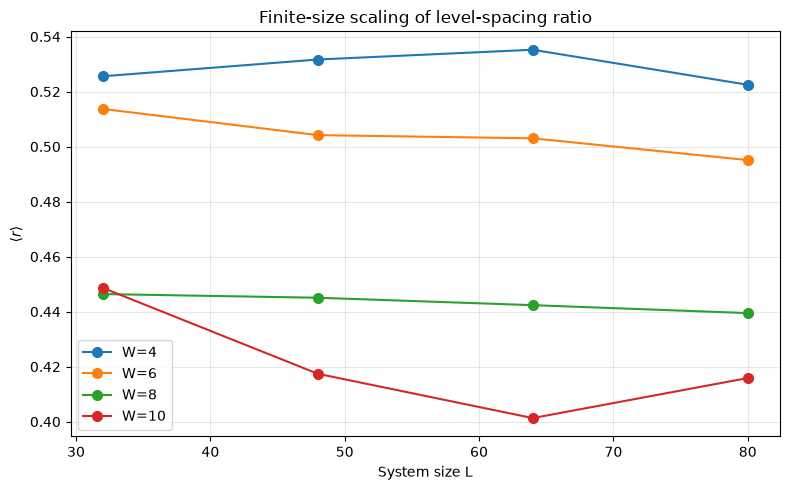

In [38]:
plt.figure(figsize=(8, 5))

for W in W_list:

    mean_r_values = [level_spacing_results[(L, W)] for L in L_list]

    plt.plot(L_list, mean_r_values, 'o-', markersize=7, label=f"W={W}")

plt.xlabel("System size L")

plt.ylabel(r"$\langle r\rangle$")

plt.title("Finite-size scaling of level-spacing ratio")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

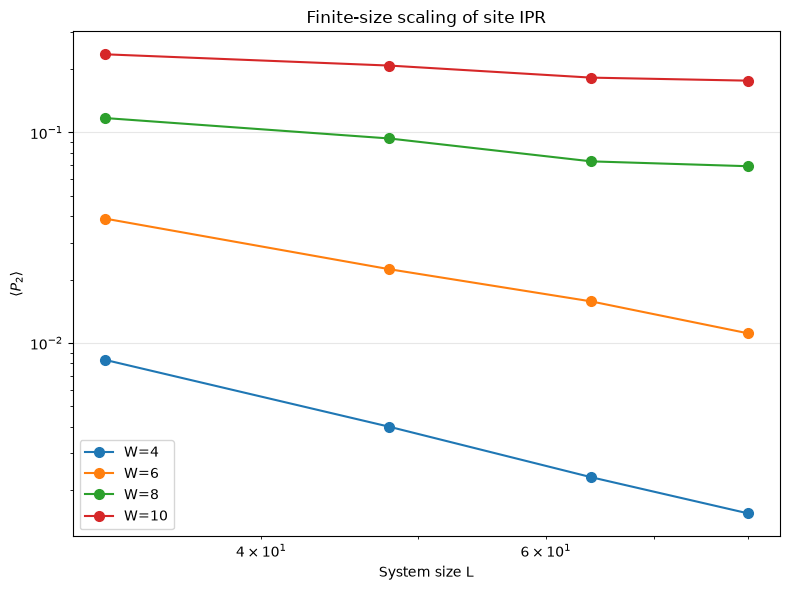

In [40]:
q = 2.0

q_index = np.where(q_list == q)[0][0]

plt.figure(figsize=(8, 6))

for W in W_list:

    IPR_values = [IPR_avg_results[(L, W)][q_index] for L in L_list]

    plt.loglog(L_list, IPR_values, 'o-', markersize=7, label=f"W={W}")

plt.xlabel("System size L")

plt.ylabel(r"$\langle P_2\rangle$")

plt.title("Finite-size scaling of site IPR")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

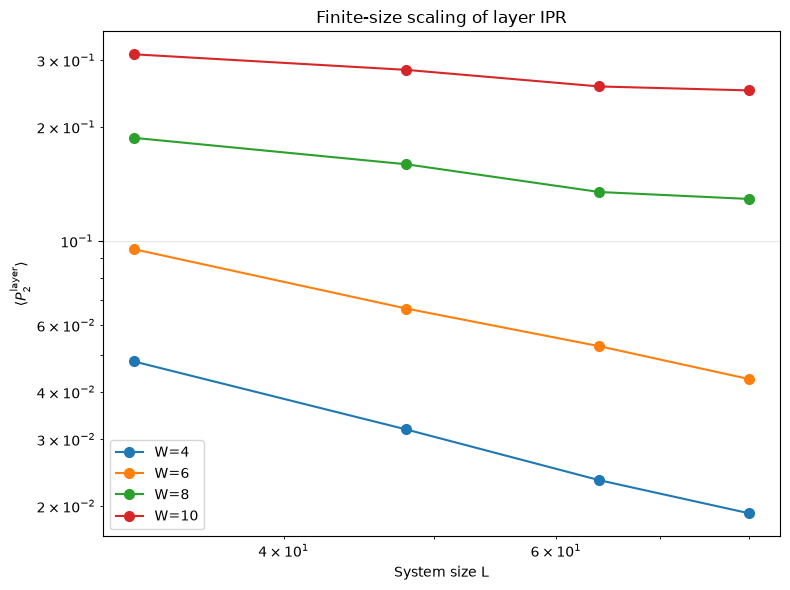

In [42]:
q = 2.0

q_index = np.where(q_list == q)[0][0]

plt.figure(figsize=(8, 6))

for W in W_list:

    Layer_IPR_values = [Layer_IPR_avg_results[(L, W)][q_index] for L in L_list]

    plt.loglog(L_list, Layer_IPR_values, 'o-', markersize=7, label=f"W={W}")

plt.xlabel("System size L")

plt.ylabel(
    r"$\langle P_2^{\mathrm{layer}}\rangle$"
)

plt.title("Finite-size scaling of layer IPR")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

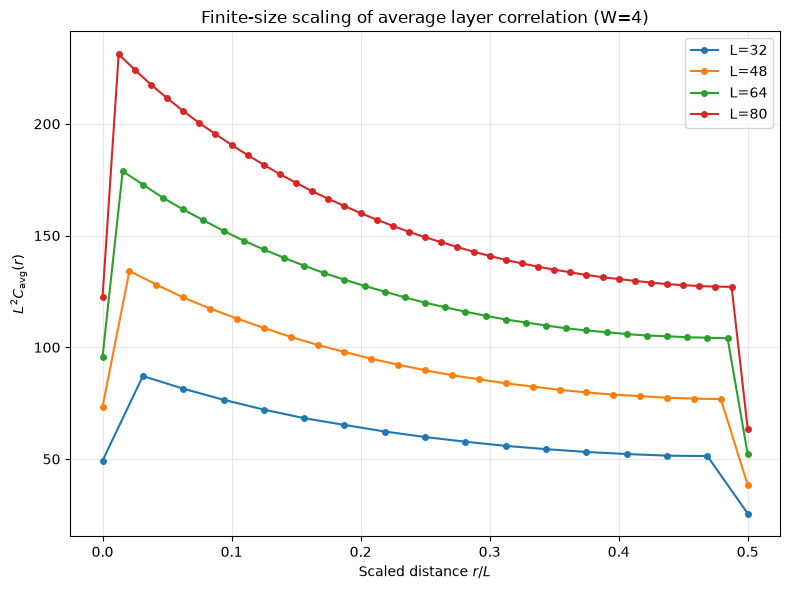

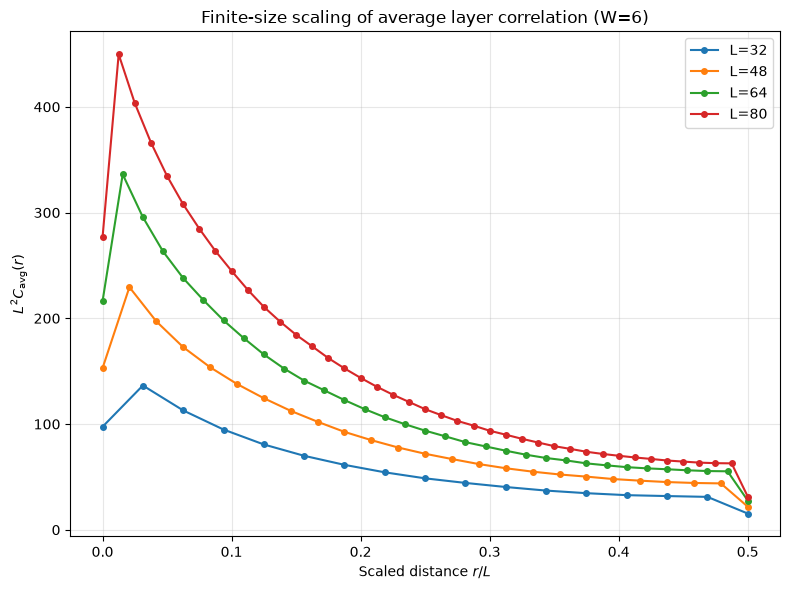

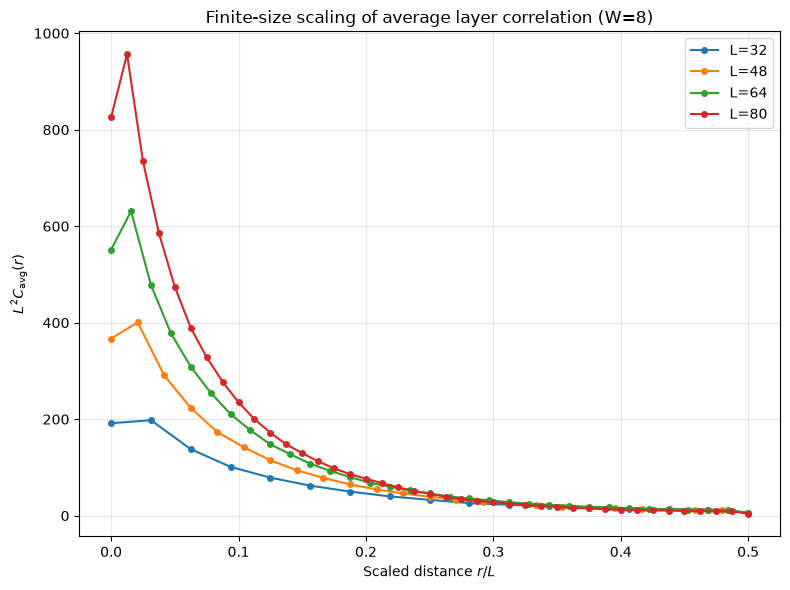

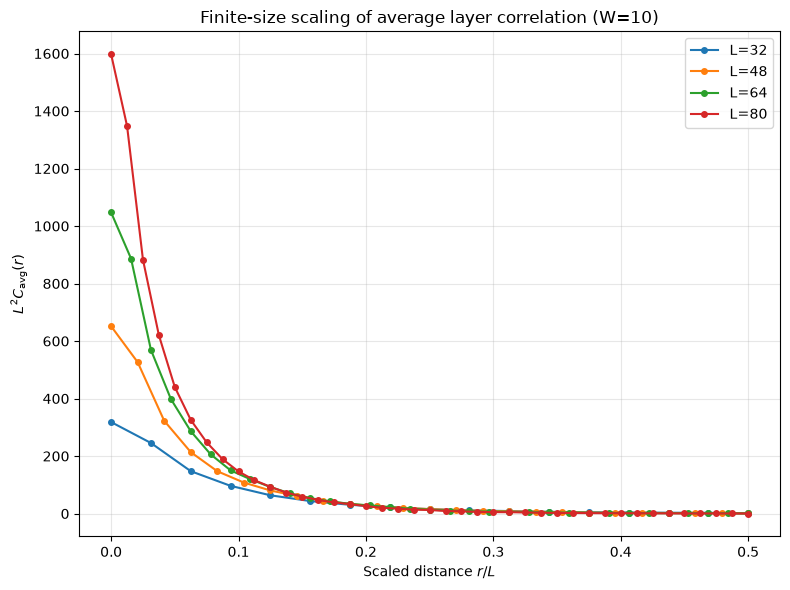

In [45]:
for W in W_list:

    plt.figure(figsize=(8, 6))

    for L in L_list:

        C_avg = C_avg_results[(L, W)]

        r = np.arange(len(C_avg))

        scaled_r = r / L

        scaled_C = L**2 * C_avg

        plt.plot(scaled_r, scaled_C, 'o-', markersize=4, label=f"L={L}")

    plt.xlabel(r"Scaled distance $r/L$")

    plt.ylabel(r"$L^2 C_{\mathrm{avg}}(r)$")

    plt.title(f"Finite-size scaling of average layer correlation (W={W})")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

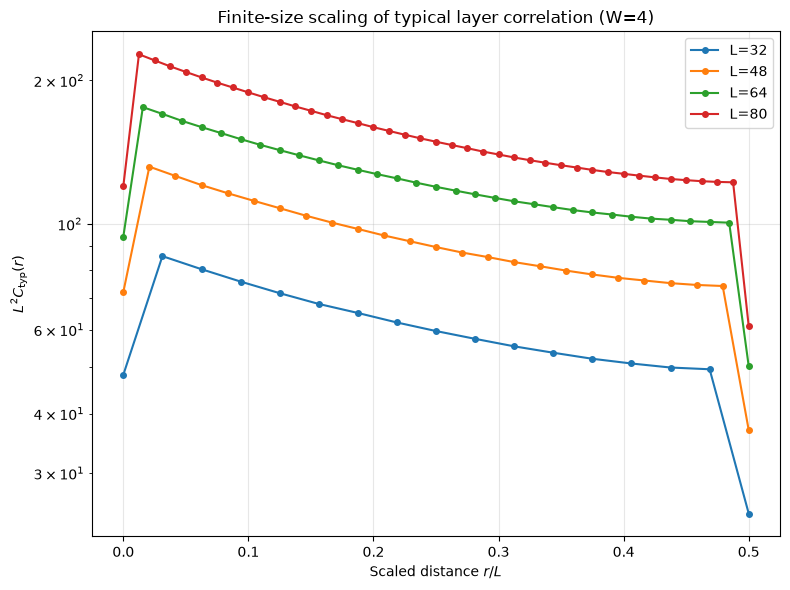

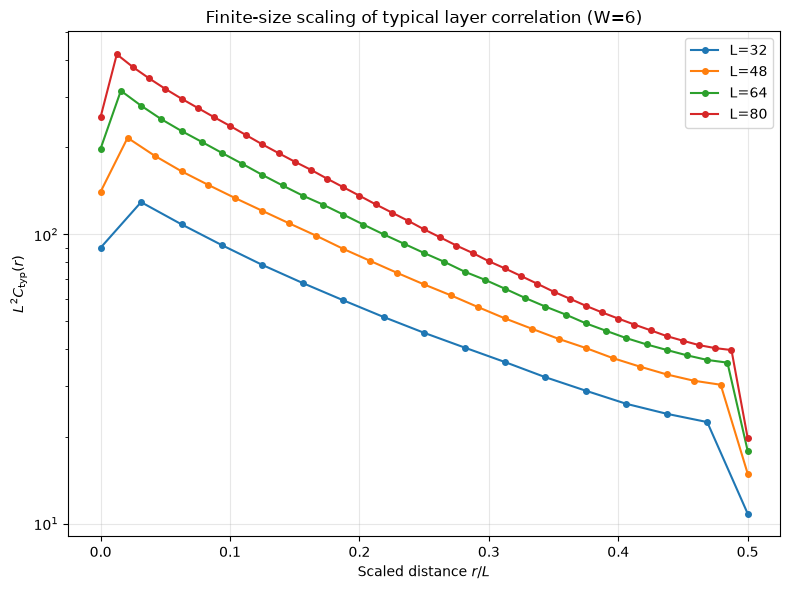

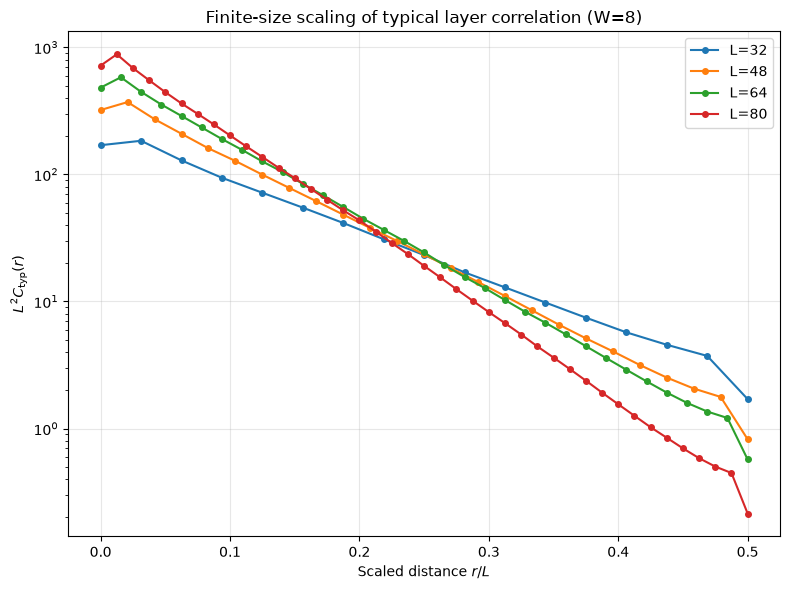

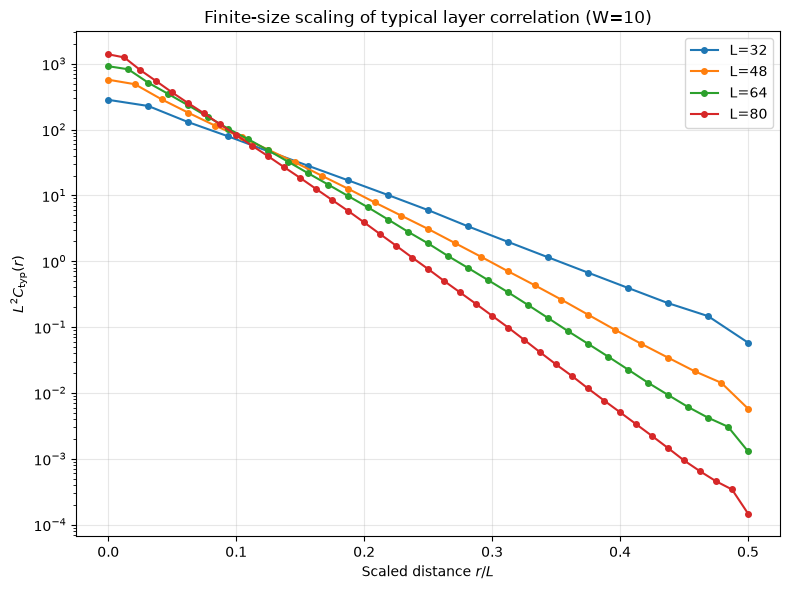

In [46]:
for W in W_list:

    plt.figure(figsize=(8, 6))

    for L in L_list:

        C_typ = C_typ_results[(L, W)]

        r = np.arange(len(C_typ))

        scaled_r = r / L

        scaled_C = L**2 * C_typ

        positive = scaled_C > 0

        plt.plot(scaled_r[positive], scaled_C[positive], 'o-', markersize=4, label=f"L={L}")

    plt.xlabel(r"Scaled distance $r/L$")

    plt.ylabel(r"$L^2 C_{\mathrm{typ}}(r)$")

    plt.title(f"Finite-size scaling of typical layer correlation (W={W})")

    plt.yscale("log")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

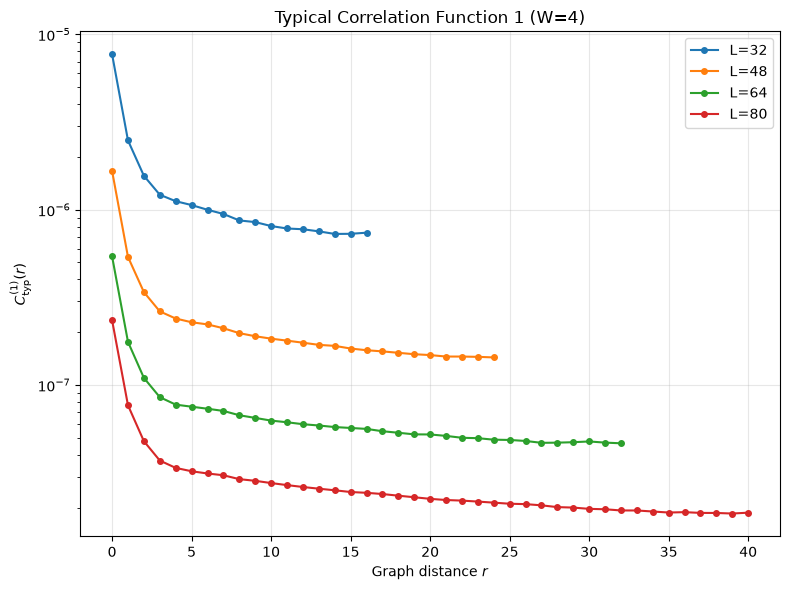

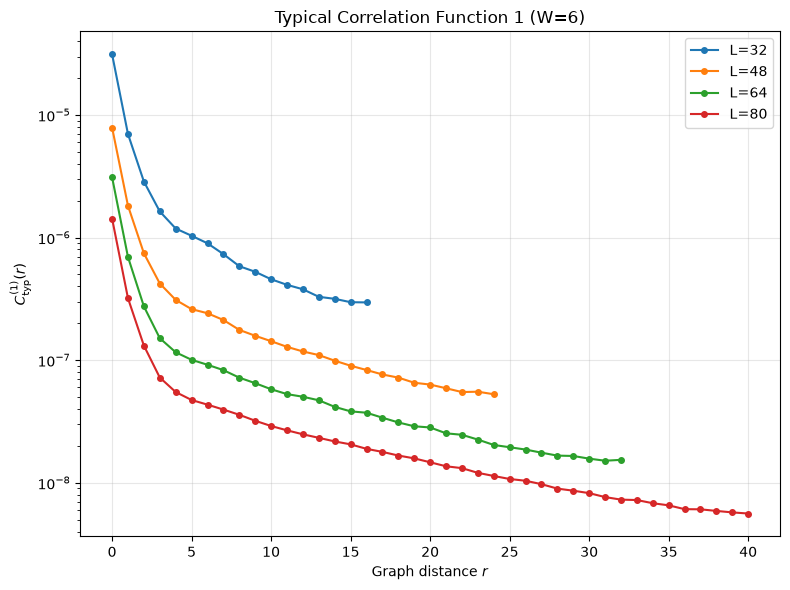

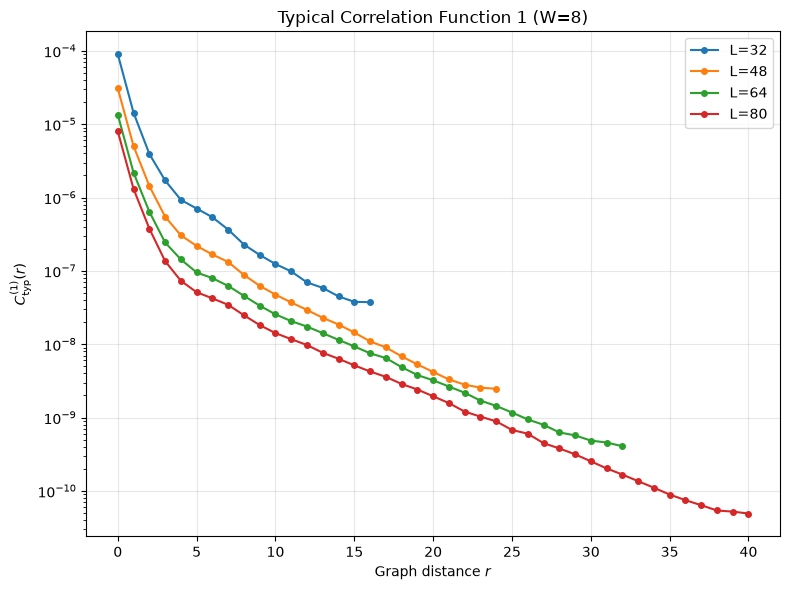

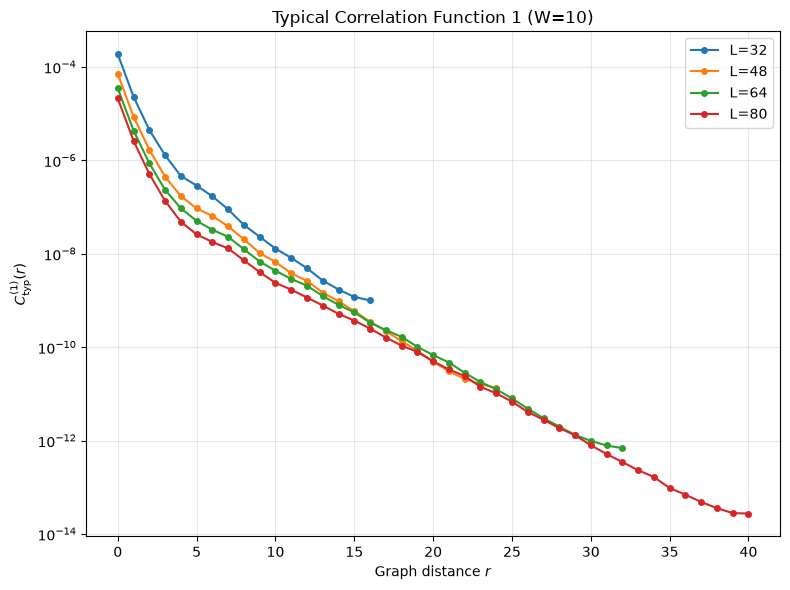

In [47]:
for W in W_list:

    plt.figure(figsize=(8, 6))

    for L in L_list:

        C1_typ = C1_typ_results[(L, W)]

        r = np.arange(len(C1_typ))

        positive = C1_typ > 0

        plt.plot(r[positive], C1_typ[positive], 'o-', markersize=4, label=f"L={L}")

    plt.xlabel(r"Graph distance $r$")

    plt.ylabel(r"$C_{\mathrm{typ}}^{(1)}(r)$")

    plt.title(f"Typical Correlation Function 1 (W={W})")

    plt.yscale("log")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

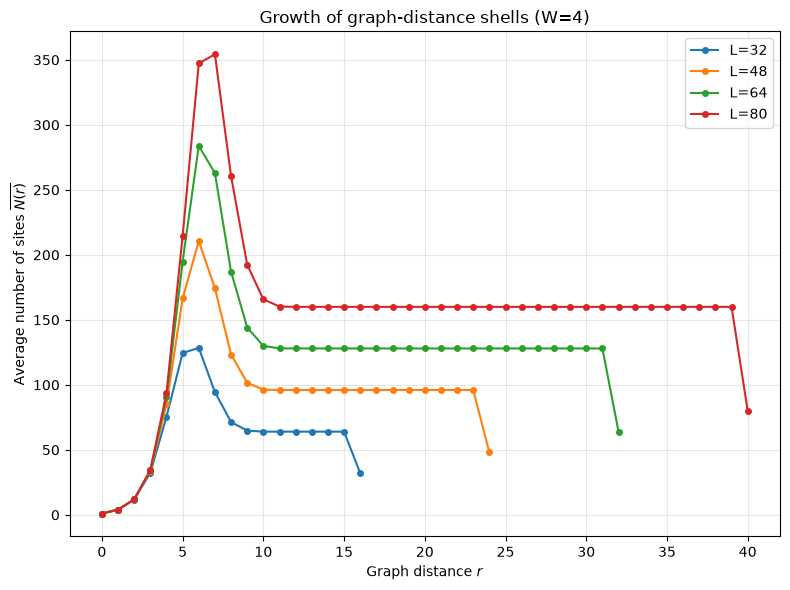

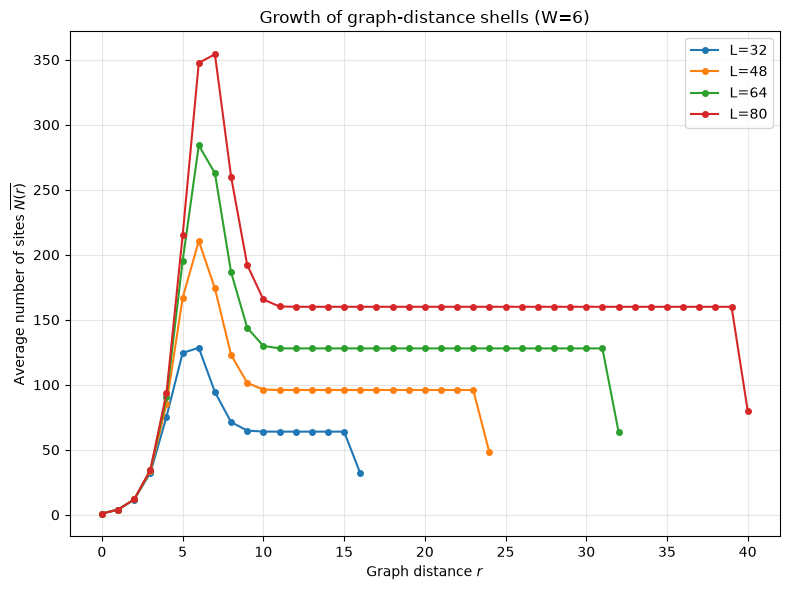

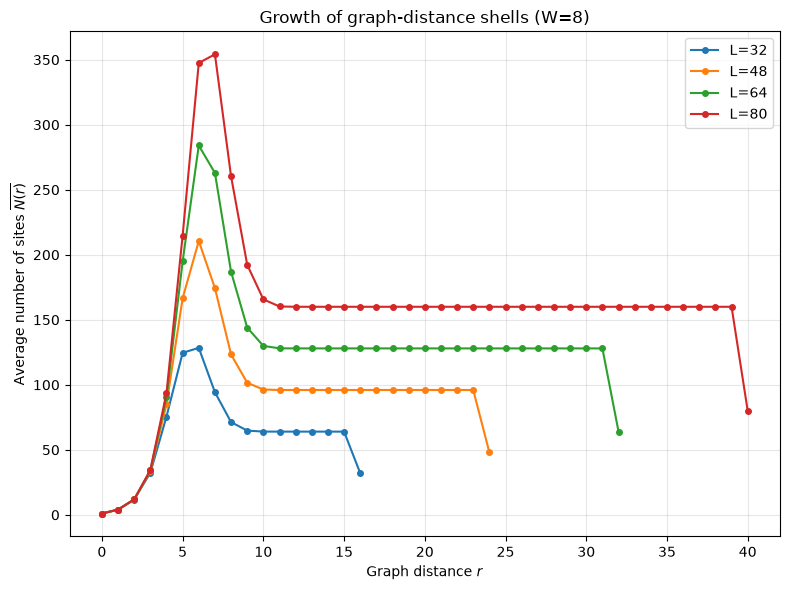

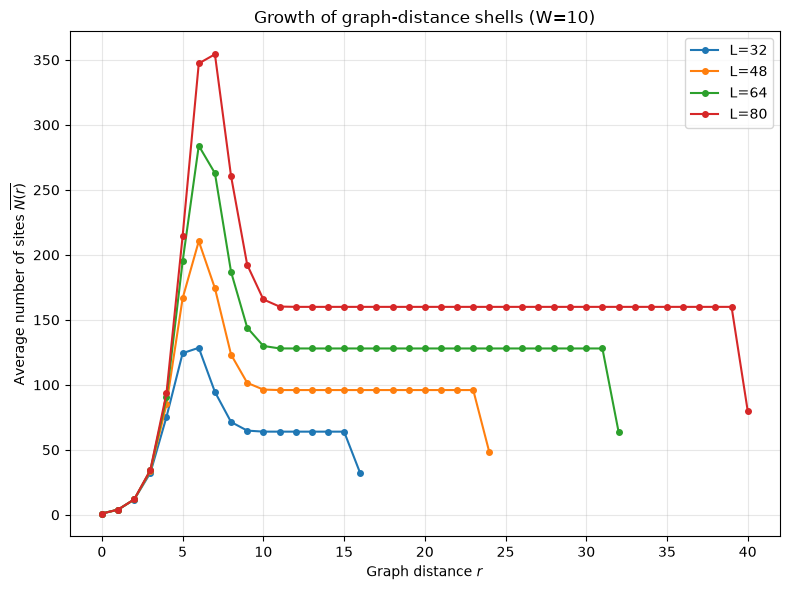

In [48]:
for W in W_list:

    plt.figure(figsize=(8, 6))

    for L in L_list:

        N_r = N_r_average_results[(L, W)]

        r = np.arange(len(N_r))

        plt.plot(r, N_r, 'o-', markersize=4, label=f"L={L}")

    plt.xlabel(r"Graph distance $r$")

    plt.ylabel(r"Average number of sites $\overline{N(r)}$")

    plt.title(f"Growth of graph-distance shells (W={W})")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

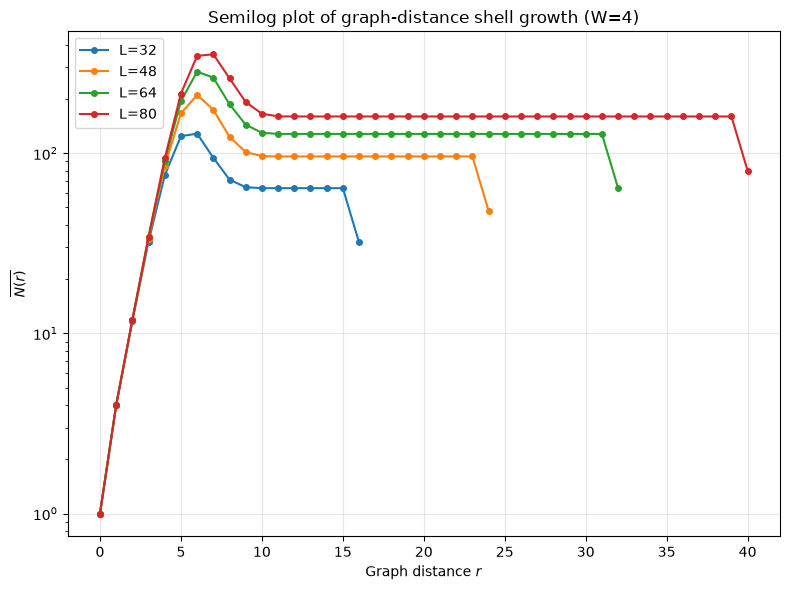

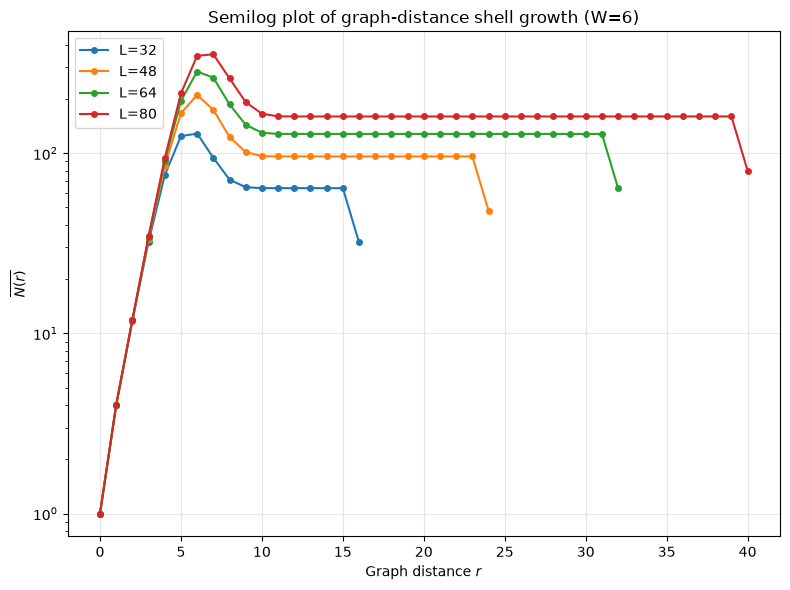

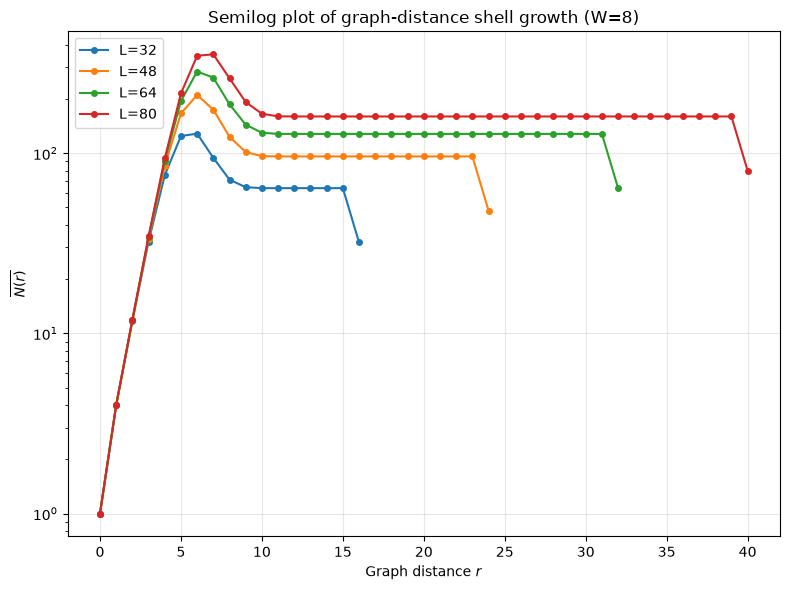

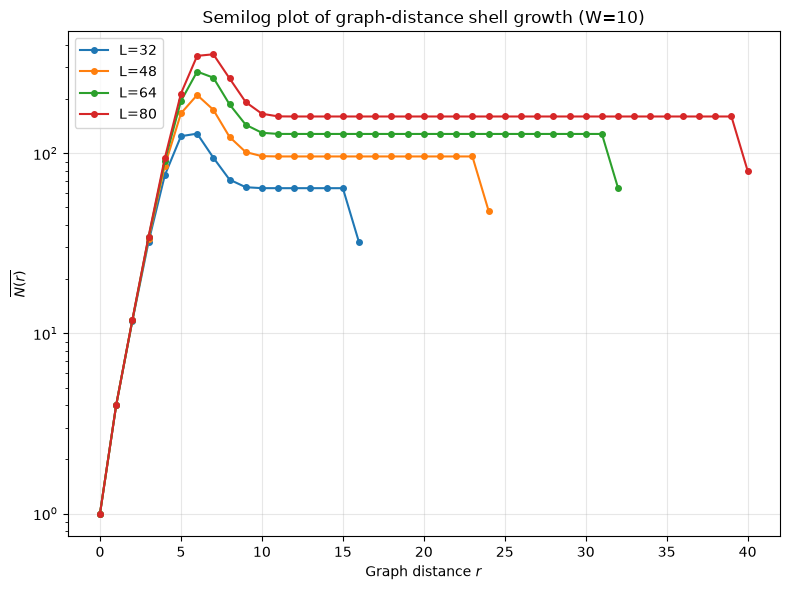

In [49]:
for W in W_list:

    plt.figure(figsize=(8, 6))

    for L in L_list:

        N_r = N_r_average_results[(L, W)]

        r = np.arange(len(N_r))

        positive = N_r > 0

        plt.semilogy(
            r[positive],
            N_r[positive],
            'o-',
            markersize=4,
            label=f"L={L}"
        )

    plt.xlabel(r"Graph distance $r$")

    plt.ylabel(r"$\overline{N(r)}$")

    plt.title(
        f"Semilog plot of graph-distance shell growth (W={W})"
    )

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

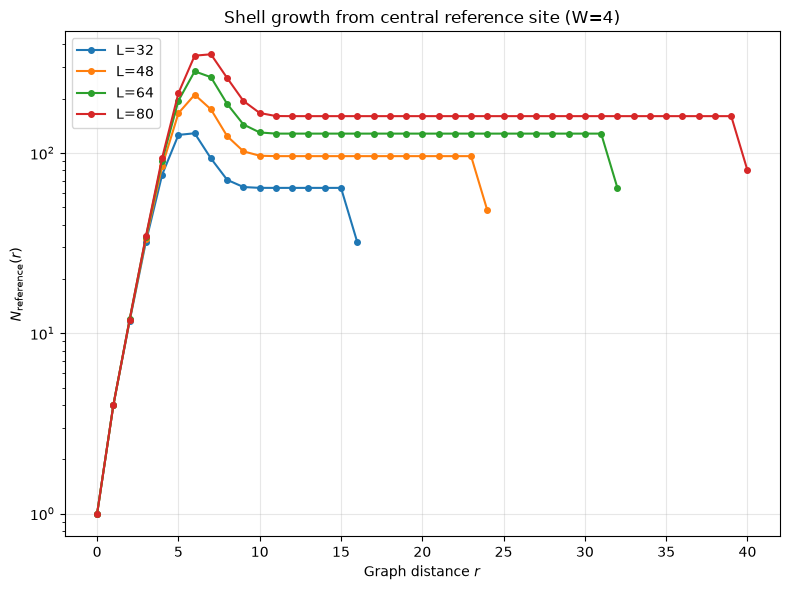

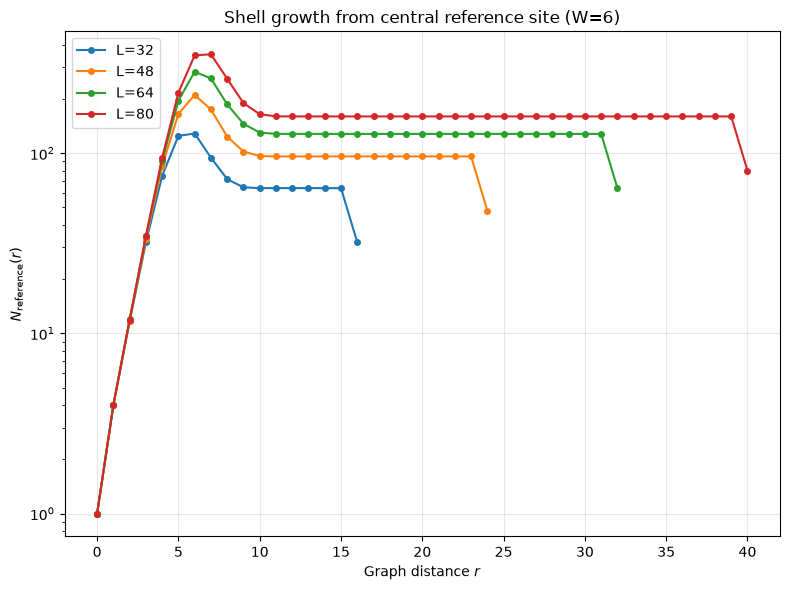

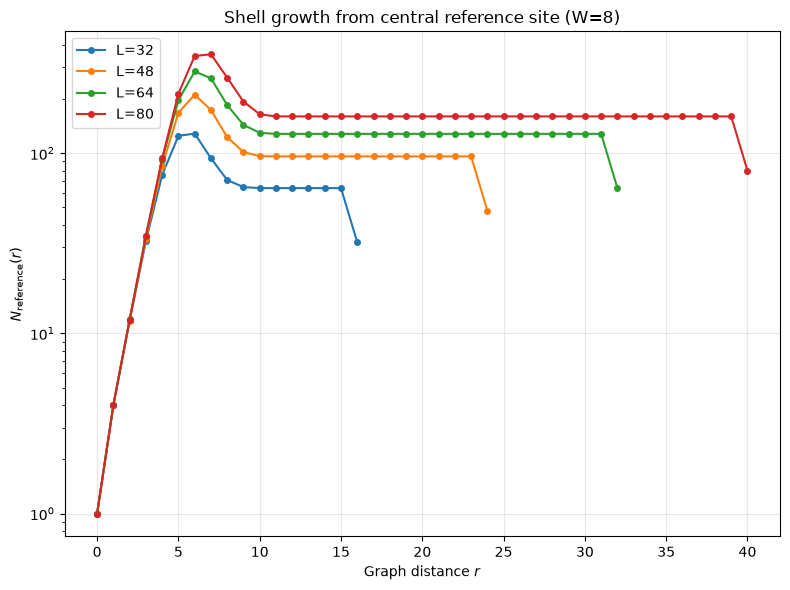

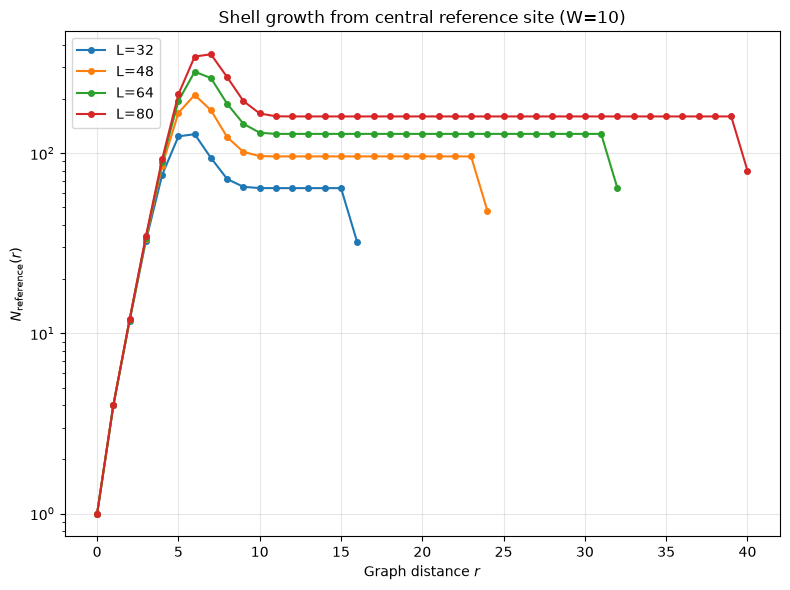

In [50]:
for W in W_list:

    plt.figure(figsize=(8, 6))

    for L in L_list:

        N_r = N_r_reference_results[(L, W)]

        r = np.arange(len(N_r))

        positive = N_r > 0

        plt.semilogy(r[positive], N_r[positive], 'o-', markersize=4, label=f"L={L}")

    plt.xlabel(r"Graph distance $r$")

    plt.ylabel(r"$N_{\mathrm{reference}}(r)$")

    plt.title(
        f"Shell growth from central reference site (W={W})"
    )

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.show()

In [51]:
# Choose the fitting interval after inspecting the semilog plot

fit_r_min = 1
fit_r_max = 7

alpha_results = {}

for W in W_list:

    alpha_results[W] = {}

    print(f"\nExponential growth rate for W={W}")

    for L in L_list:

        N_r = N_r_average_results[(L, W)]

        r = np.arange(len(N_r))

        mask = ((r >= fit_r_min) & (r <= fit_r_max) & (N_r > 0))

        if np.sum(mask) < 2:

            print(f"L={L}: Not enough points for fitting")

            continue

        result = linregress(r[mask], np.log(N_r[mask]))

        alpha = result.slope

        alpha_results[W][L] = alpha

        print(f"L={L}: alpha = {alpha:.6f}, " f"R-squared = {result.rvalue**2:.6f}")


Exponential growth rate for W=4
L=32: alpha = 0.557727, R-squared = 0.818655
L=48: alpha = 0.667359, R-squared = 0.892485
L=64: alpha = 0.737358, R-squared = 0.927268
L=80: alpha = 0.786648, R-squared = 0.947100

Exponential growth rate for W=6
L=32: alpha = 0.557829, R-squared = 0.818836
L=48: alpha = 0.667248, R-squared = 0.892037
L=64: alpha = 0.737390, R-squared = 0.927048
L=80: alpha = 0.786719, R-squared = 0.946962

Exponential growth rate for W=8
L=32: alpha = 0.557593, R-squared = 0.818293
L=48: alpha = 0.667423, R-squared = 0.892539
L=64: alpha = 0.737449, R-squared = 0.927309
L=80: alpha = 0.786689, R-squared = 0.947010

Exponential growth rate for W=10
L=32: alpha = 0.557969, R-squared = 0.819317
L=48: alpha = 0.667348, R-squared = 0.892402
L=64: alpha = 0.737425, R-squared = 0.927243
L=80: alpha = 0.786661, R-squared = 0.947108


In [53]:
tau_results = {}

for W in W_list:

    tau = []

    for i, q in enumerate(q_list):

        IPR_values = np.array([IPR_avg_results[(L, W)][i] for L in L_list])

        slope, intercept = np.polyfit(np.log(L_list), np.log(IPR_values), 1)

        tau.append(-slope)

    tau_results[W] = np.array(tau)

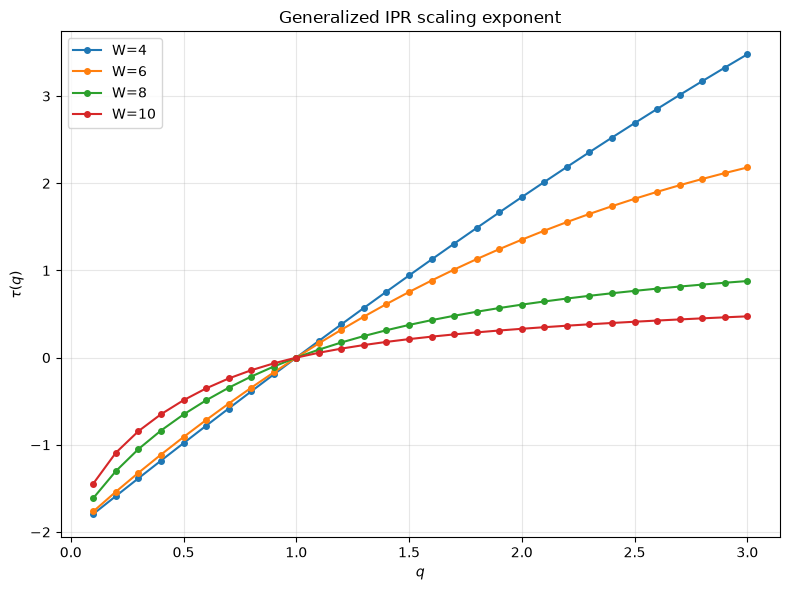

In [55]:
plt.figure(figsize=(8, 6))

for W in W_list:

    plt.plot(q_list, tau_results[W], 'o-', markersize=4, label=f"W={W}")

plt.xlabel(r"$q$")

plt.ylabel(r"$\tau(q)$")

plt.title("Generalized IPR scaling exponent")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [57]:
for L in L_list:

    for W in W_list:

        C_avg = C_avg_results[(L, W)]

        print(f"L={L}, W={W}: " f"Sum C_avg = {np.sum(C_avg):.12f}")

L=32, W=4: Sum C_avg = 1.000000000000
L=32, W=6: Sum C_avg = 1.000000000000
L=32, W=8: Sum C_avg = 1.000000000000
L=32, W=10: Sum C_avg = 1.000000000000
L=48, W=4: Sum C_avg = 1.000000000000
L=48, W=6: Sum C_avg = 1.000000000000
L=48, W=8: Sum C_avg = 1.000000000000
L=48, W=10: Sum C_avg = 1.000000000000
L=64, W=4: Sum C_avg = 1.000000000000
L=64, W=6: Sum C_avg = 1.000000000000
L=64, W=8: Sum C_avg = 1.000000000000
L=64, W=10: Sum C_avg = 1.000000000000
L=80, W=4: Sum C_avg = 1.000000000000
L=80, W=6: Sum C_avg = 1.000000000000
L=80, W=8: Sum C_avg = 1.000000000000
L=80, W=10: Sum C_avg = 1.000000000000
